# SDE fitting on a iPSC reprogramming dataset

Here, we use the iPSC reprogramming dataset by [Schiebinger et al. 2019](https://doi.org/10.1016/j.cell.2019.01.006), obtained from the [WOT tutorial](https://broadinstitute.github.io/wot/tutorial/) to fit a gene regulatory SDE model using a PseudotimeDataset, with cells sampled at different experimental time points.
We only use a small subset of genes that Schiebinger et al. described as important regulators of the various fates during reprogramming.

We adjust the loss to put more weight on the later time points and add a sparsity penalty (L1) for the adjacency matrix.

We use the model trained with optimized hyperparameters (including regularization strength), where the early-stopping patience was set to 100 epochs instead of the default 5. Train/validation/test splitting was done based on time points.

In [1]:
import random
from pathlib import Path

import anndata
import networkx as nx
import numpy as np
import optuna
import pandas as pd
import scanpy as sc
import seaborn as sns
import torch
from bowside.dataset import PseudotimeDataset
from bowside.mixture import GaussianMixtureTimeseries
from bowside.model import GRNModelSDE
from bowside.sensitivity import simulate_all_knockouts
from bowside.training import integrate_model, sinkhorn_loss
from bowside.trajectory import infer_cell_fates, infer_trajectories
from matplotlib import pyplot as plt
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend
from scipy import stats
from scipy.cluster.hierarchy import fcluster

In [2]:
# Make output directory
OUT_DIR = Path("../output/ipscs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Load data
name = "weighted_sinkhorn_time_point_split_fully_connected_smoothed"
adata = sc.read_h5ad("../data/ipscs_processed_smoothed.h5ad")
display(adata)
adj_list = pd.read_csv("../data/grns/tflink_mm.csv")
display(adj_list)
study = optuna.load_study(
    study_name=f"ipscs_MAGIC_tuning_{name}",
    storage=JournalStorage(
        JournalFileBackend(f"../output/tuning/ipscs/{name}/journal.log")
    ),
)

AnnData object with n_obs × n_vars = 165892 × 1492
    obs: 'day', 'batch', 'cell_set'
    var: 'highly_variable', 'mean', 'std', 'MET_gene', 'stromal_gene', 'epithelial_gene', 'trophoblast_gene', 'neural_gene', 'iPSC_gene', 'reprogramming_gene'
    uns: 'DM_EigenValues', 'cell_set_colors', 'neighbors', 'pca'
    obsm: 'DM_EigenVectors', 'DM_EigenVectors_multiscaled', 'X_fle', 'X_pca'
    varm: 'PCs'
    obsp: 'DM_Kernel', 'DM_Similarity', 'connectivities', 'distances'
    layers: 'MAGIC_imputed_data', 'log1p', None

,source,target,small_scale
0,Rfx5,H2-Ab1,Yes
1,Rela,Trim63,Yes
2,Creb1,Chgb,Yes
3,Mybl1,Rfx2,Yes
4,Hif1a,Bax,Yes
...,...,...,...
4057577,Smyd3,Slc38a10,No
4057578,Stag2,Rtp4,No
4057579,Sirt6,Ppp1r3e,No
4057580,Nr4a1,Mrpl49,No


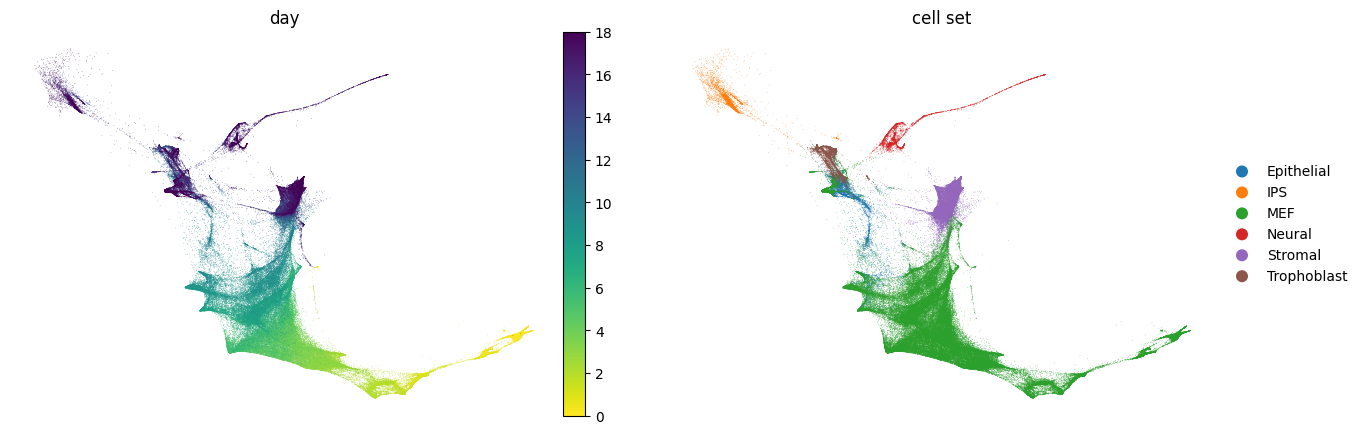

In [4]:
# Look at the data
sc.pl.scatter(
    adata, basis="fle", color=["day", "cell_set"], color_map="viridis_r", right_margin=0.2, frameon=False
)

In [5]:
# Select reprogramming genes
adata.var[adata.var["reprogramming_gene"]]

,highly_variable,mean,std,MET_gene,stromal_gene,epithelial_gene,trophoblast_gene,neural_gene,iPSC_gene,reprogramming_gene
index,,,,,,,,,,
Msc,False,0.003424,0.052190,False,False,False,False,False,True,True
Prrx1,True,0.505783,0.667108,False,True,False,False,False,False,True
Gata3,True,0.028741,0.171060,False,False,True,False,False,False,True
Elf5,False,0.009613,0.095144,False,False,True,False,False,False,True
Ovol2,False,0.017733,0.118446,False,False,True,False,False,False,True
Scrt2,True,0.003228,0.065424,False,False,False,False,True,False,True
Mybl2,False,0.195578,0.395466,False,False,False,False,False,True,True
Zic3,False,0.015694,0.112636,True,False,False,False,False,False,True
Csf1,True,0.215908,0.449954,False,True,False,False,False,False,True


In [6]:
# Use only reprogramming genes
layer = "MAGIC_imputed_data"
time_points = np.arange(0, 18.5, 0.5).tolist()
time_points.extend([8.25, 8.75])
time_points = sorted(time_points)
dataset = PseudotimeDataset(
    adata,
    layer=layer,
    mask_var="reprogramming_gene",
    pseudotime_key="day",
    time_points=time_points,
)

In [7]:
# Make input GRN
grn = nx.from_pandas_edgelist(
    adj_list[
        (adj_list["source"].isin(dataset.gene_names))
        & (adj_list["target"].isin(dataset.gene_names))
    ],
    source="source",
    target="target",
    create_using=nx.DiGraph,
)
for gene in dataset.gene_names:
    if gene not in grn.nodes():
        grn.add_node(gene)

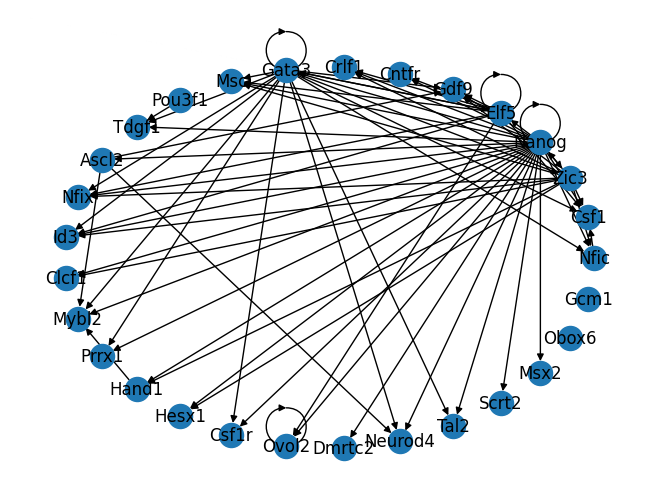

In [8]:
nx.draw_circular(grn, with_labels=True)

In [9]:
study.best_params

{'adj_init_normal': 'False',
 'sigma': 0.054009005681004835,
 'shared_sigma': 'True',
 'fixed_sigma': 'False',
 'constant_noise': 'False',
 'optimizer': 'RMSprop',
 'lr': 0.029172920268953365,
 'num_epochs': 4000,
 'solver_method': 'milstein',
 'regularization_strength': 2.3146544718622888e-05}

In [10]:
trials_df = study.trials_dataframe().sort_values(by="value")
trials_df

,number,value,datetime_start,datetime_complete,duration,params_adj_init_normal,params_constant_noise,params_fixed_sigma,params_lr,params_num_epochs,params_optimizer,params_regularization_strength,params_shared_sigma,params_sigma,params_solver_method,state
114,114,2.139114e-01,2026-08-27 15:42:38.289678,2026-08-27 15:52:51.706789,0 days 00:10:13.417111,False,False,False,0.029173,4000.0,RMSprop,0.000023,True,0.054009,milstein,COMPLETE
168,168,2.246167e-01,2026-08-27 18:16:33.980496,2026-08-27 18:29:30.385616,0 days 00:12:56.405120,False,False,False,0.019456,3500.0,RMSprop,0.000017,True,0.035115,milstein,COMPLETE
134,134,2.319949e-01,2026-08-27 16:31:01.180142,2026-08-27 16:44:54.780464,0 days 00:13:53.600322,False,False,False,0.016091,4500.0,RMSprop,0.000021,True,0.030128,milstein,COMPLETE
58,58,2.333096e-01,2026-08-27 13:04:57.865950,2026-08-27 13:15:41.906610,0 days 00:10:44.040660,False,False,False,0.064475,3500.0,RMSprop,0.000018,True,0.065497,milstein,COMPLETE
115,115,2.378643e-01,2026-08-27 15:44:01.567857,2026-08-27 15:53:24.883380,0 days 00:09:23.315523,False,False,False,0.029065,4000.0,RMSprop,0.000022,True,0.056408,milstein,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,152,6.577184e+07,2026-08-27 17:32:14.087113,2026-08-27 17:35:22.174341,0 days 00:03:08.087228,False,False,False,0.020806,4000.0,RMSprop,0.000019,True,4.542842,milstein,COMPLETE
6,6,NaN,2026-08-27 10:47:05.699503,2026-08-27 10:47:15.312932,0 days 00:00:09.613429,False,False,True,NaN,NaN,NaN,NaN,False,3.586618,NaN,PRUNED
10,10,NaN,2026-08-27 10:54:57.288283,2026-08-27 10:55:06.739782,0 days 00:00:09.451499,False,True,True,NaN,NaN,NaN,NaN,False,0.290502,NaN,PRUNED
11,11,NaN,2026-08-27 10:55:06.748318,2026-08-27 10:55:16.195096,0 days 00:00:09.446778,True,True,True,NaN,NaN,NaN,NaN,False,0.968571,NaN,PRUNED


In [11]:
# Setup
rank = 1  # get <rank>-best model
params = trials_df.iloc[rank - 1].to_dict()
sigma = params["params_sigma"]
adj_init_normal = (params["params_adj_init_normal"] == "True")
shared_sigma = (params["params_shared_sigma"] == "True")
fixed_sigma = (params["params_fixed_sigma"] == "True")
constant_noise = (params["params_constant_noise"] == "True")

model = GRNModelSDE(
    dataset.n_genes(),
    adj=None,  # torch.ones(dataset.n_genes(), dataset.n_genes()),
    adj_init_normal=adj_init_normal,
    activation="sigmoid",
    sigma=sigma,
    shared_sigma=shared_sigma,
    fixed_sigma=fixed_sigma,
    constant_noise=constant_noise,
)

In [12]:
# Load model
trial_number = params["number"]
checkpoint_dir = f"../output/tuning/ipscs/{name}/{trial_number}/"
checkpoint = torch.load(
    f"{checkpoint_dir}/checkpoint_final_model.tar", weights_only=True, map_location=torch.device('cpu')
)
model.load_state_dict(checkpoint["model_state_dict"])
train_losses = np.load(f"{checkpoint_dir}/train_losses.npy")
test_losses = np.load(f"{checkpoint_dir}/test_losses.npy")

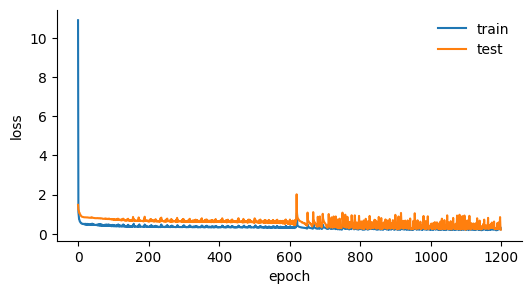

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))

ax.plot(train_losses, label="train")
ax.plot(test_losses, label="test")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.legend(loc="upper right", frameon=False)
sns.despine(fig);

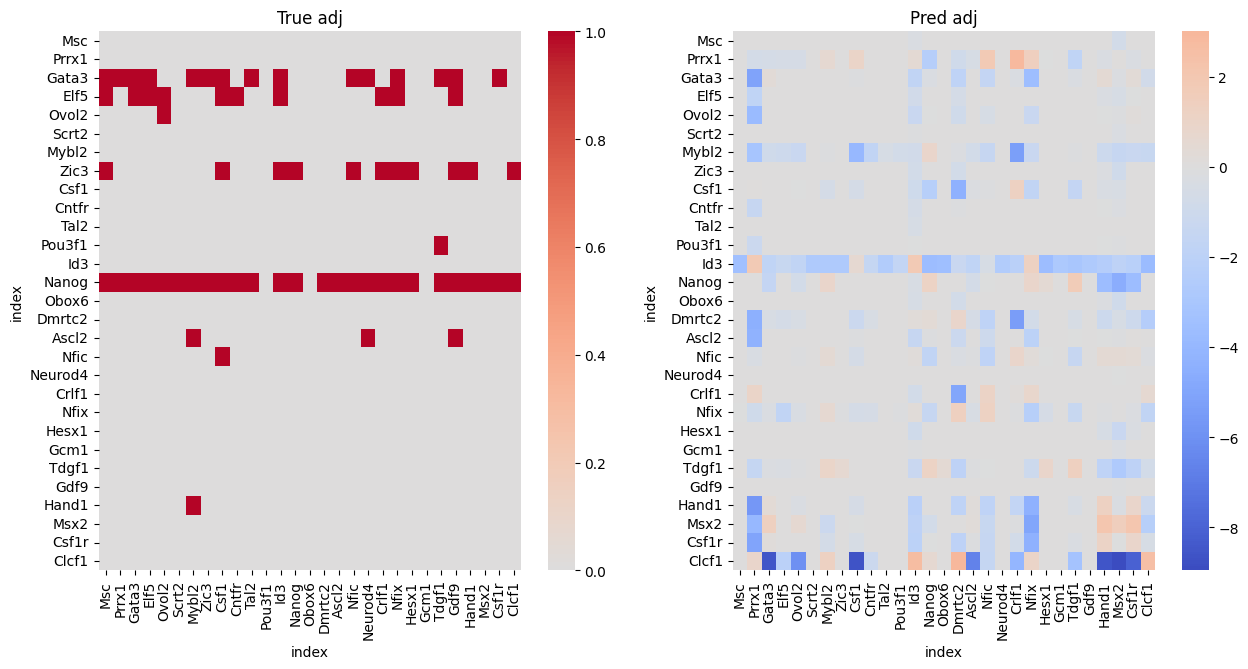

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

sns.heatmap(
    nx.to_pandas_adjacency(grn, weight="effect", nodelist=dataset.gene_names),
    annot=False,
    cmap="coolwarm",
    center=0,
    ax=axs[0],
)
axs[0].set_title("True adj")
sns.heatmap(
    pd.DataFrame(
        model.adj.detach(),
        index=dataset.gene_names,
        columns=dataset.gene_names,
    ),
    annot=False,
    cmap="coolwarm",
    center=0,
    ax=axs[1],
)
axs[1].set_title("Pred adj");

In [15]:
y = dataset[:]
y0 = y[:, 0, :]
ts = dataset.time_points
dt = 0.1

pred = integrate_model(
    model, y0, time_points=ts, solver_method=params["params_solver_method"]
)

In [16]:
alpha = 10.0 / len(dataset)

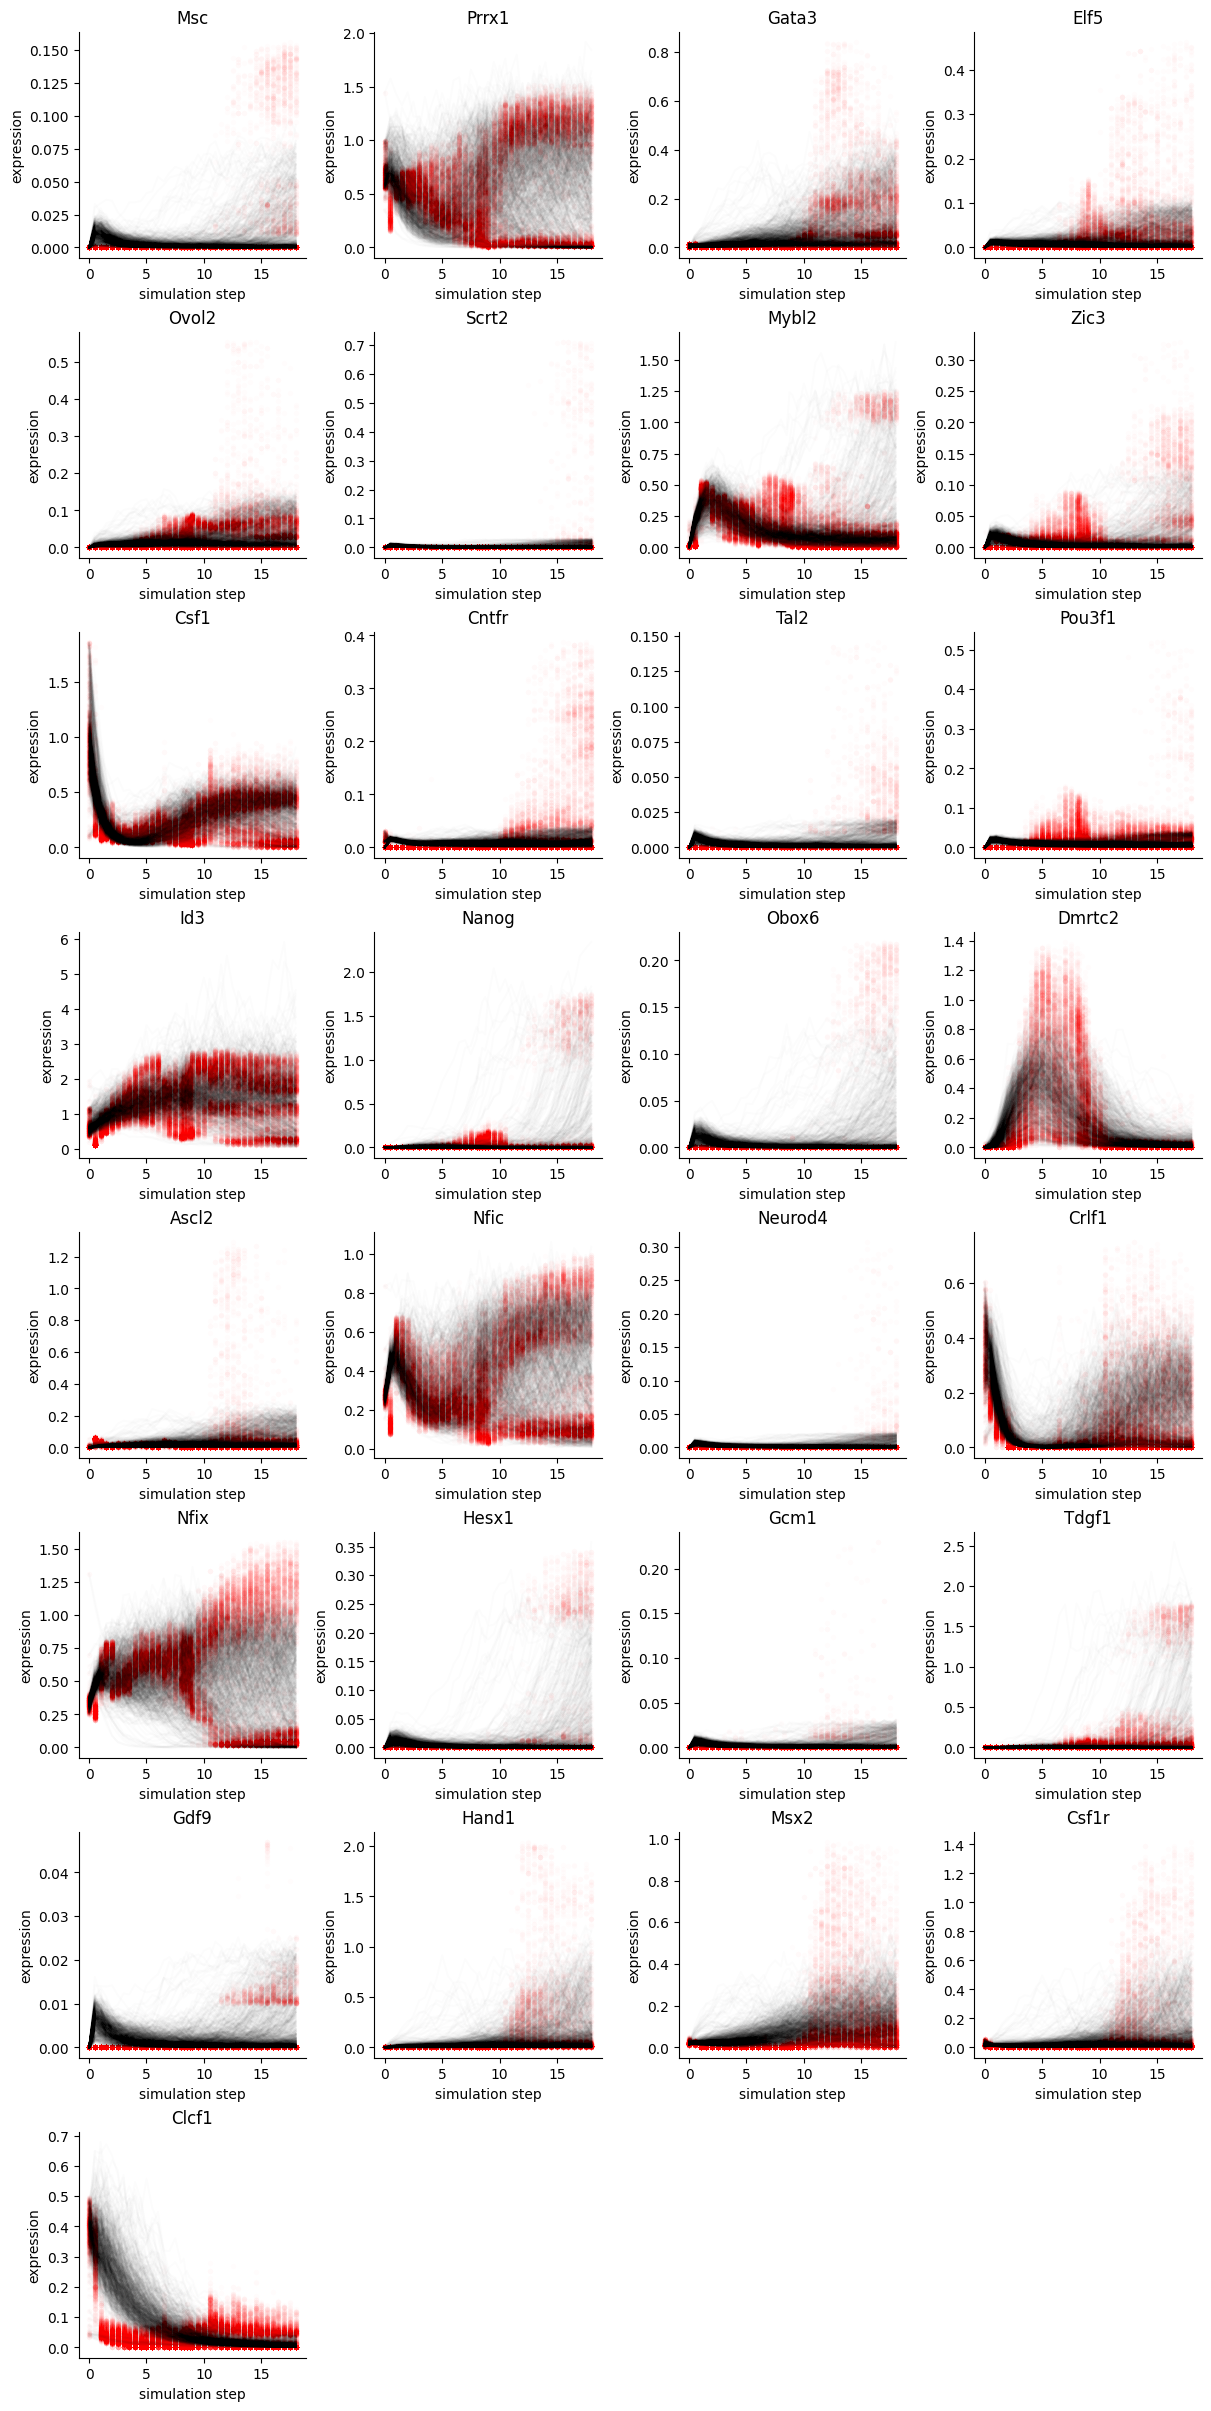

In [17]:
n_rows = dataset.n_genes() // 4 + 1
n_cols = 4
fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3), layout="constrained"
)

for i, ax in enumerate(axs.flat):
    if i < len(dataset.gene_names):
        gene_name = dataset.gene_names[i]
        ax.scatter(
            ts.cpu().repeat((dataset[:].shape[0], 1)),
            y[:, :, i].detach().cpu(),
            color="r",
            linewidth=0,
            s=15,
            alpha=alpha,
        )
        ax.plot(
            ts.cpu(),
            pred[:, :, i].detach().cpu(),
            color="k",
            alpha=alpha,
        )
        ax.set_xlabel("simulation step")
        ax.set_ylabel("expression")
        ax.set_title(gene_name)
    else:
        ax.set_axis_off()

sns.despine(fig);

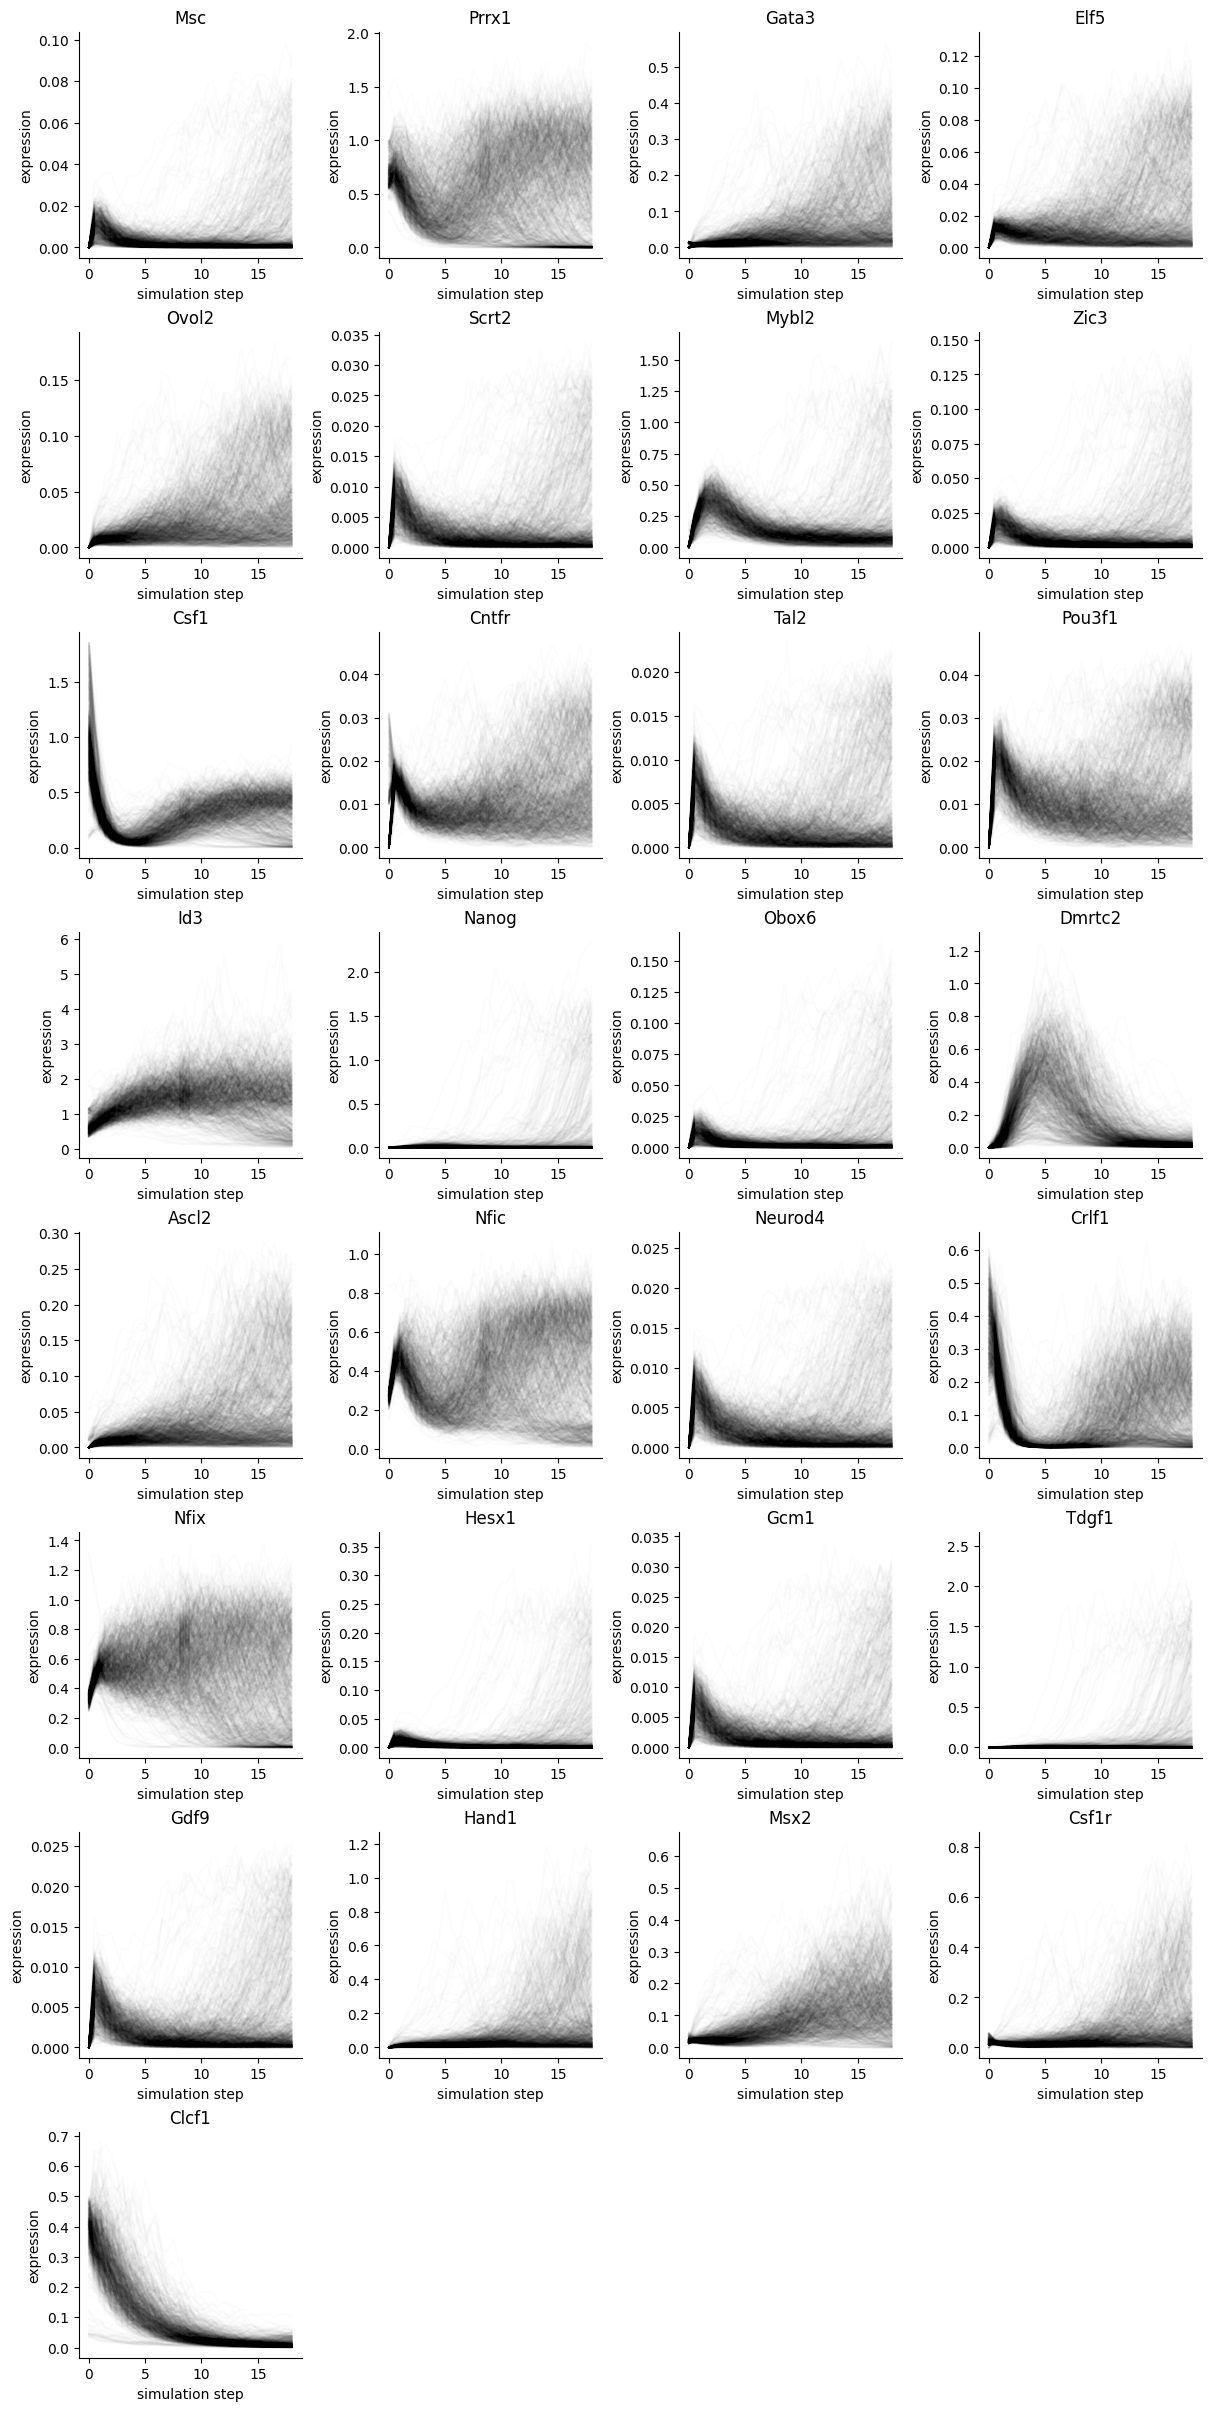

In [18]:
n_rows = dataset.n_genes() // 4 + 1
n_cols = 4
fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3), layout="constrained"
)

for i, ax in enumerate(axs.flat):
    if i < len(dataset.gene_names):
        gene_name = dataset.gene_names[i]
        ax.plot(
            ts.cpu(),
            pred[:, :, i].detach().cpu(),
            color="k",
            alpha=alpha,
        )
        ax.set_xlabel("simulation step")
        ax.set_ylabel("expression")
        ax.set_title(gene_name)
    else:
        ax.set_axis_off()

sns.despine(fig);

In [19]:
# Perform trajectory inference with the fitted model
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
infer_trajectories(
    dataset, model, dt=dt, solver_method=params["params_solver_method"]
)

# Three trajectories is not much worse than two (see silhouette scores)
# -> set three trajectories
cluster_labels = fcluster(
    adata.uns["bowside"]["trajectory_inference_linkage"], 3, criterion="maxclust"
)
sequences = adata.uns["bowside"]["simulations"]
trajectories = np.zeros((3, sequences.shape[0], sequences.shape[2]))
for i, cluster in enumerate(np.unique(cluster_labels, sorted=True)):
    cluster_sequences = sequences[:, cluster_labels == cluster, :]
    trajectories[i] = cluster_sequences.mean(axis=1)
# Store three trajectories
adata.uns["bowside"]["num_trajectories"] = 3
adata.uns["bowside"]["trajectory_inference_clusters"] = cluster_labels
adata.uns["bowside"]["trajectories"] = trajectories

infer_cell_fates(dataset, allow_singular_covariance=True)

# Perform KO simulations
_, _ = simulate_all_knockouts(
    dataset, model, sinkhorn_loss, dt=dt, solver_method=params["params_solver_method"]
)

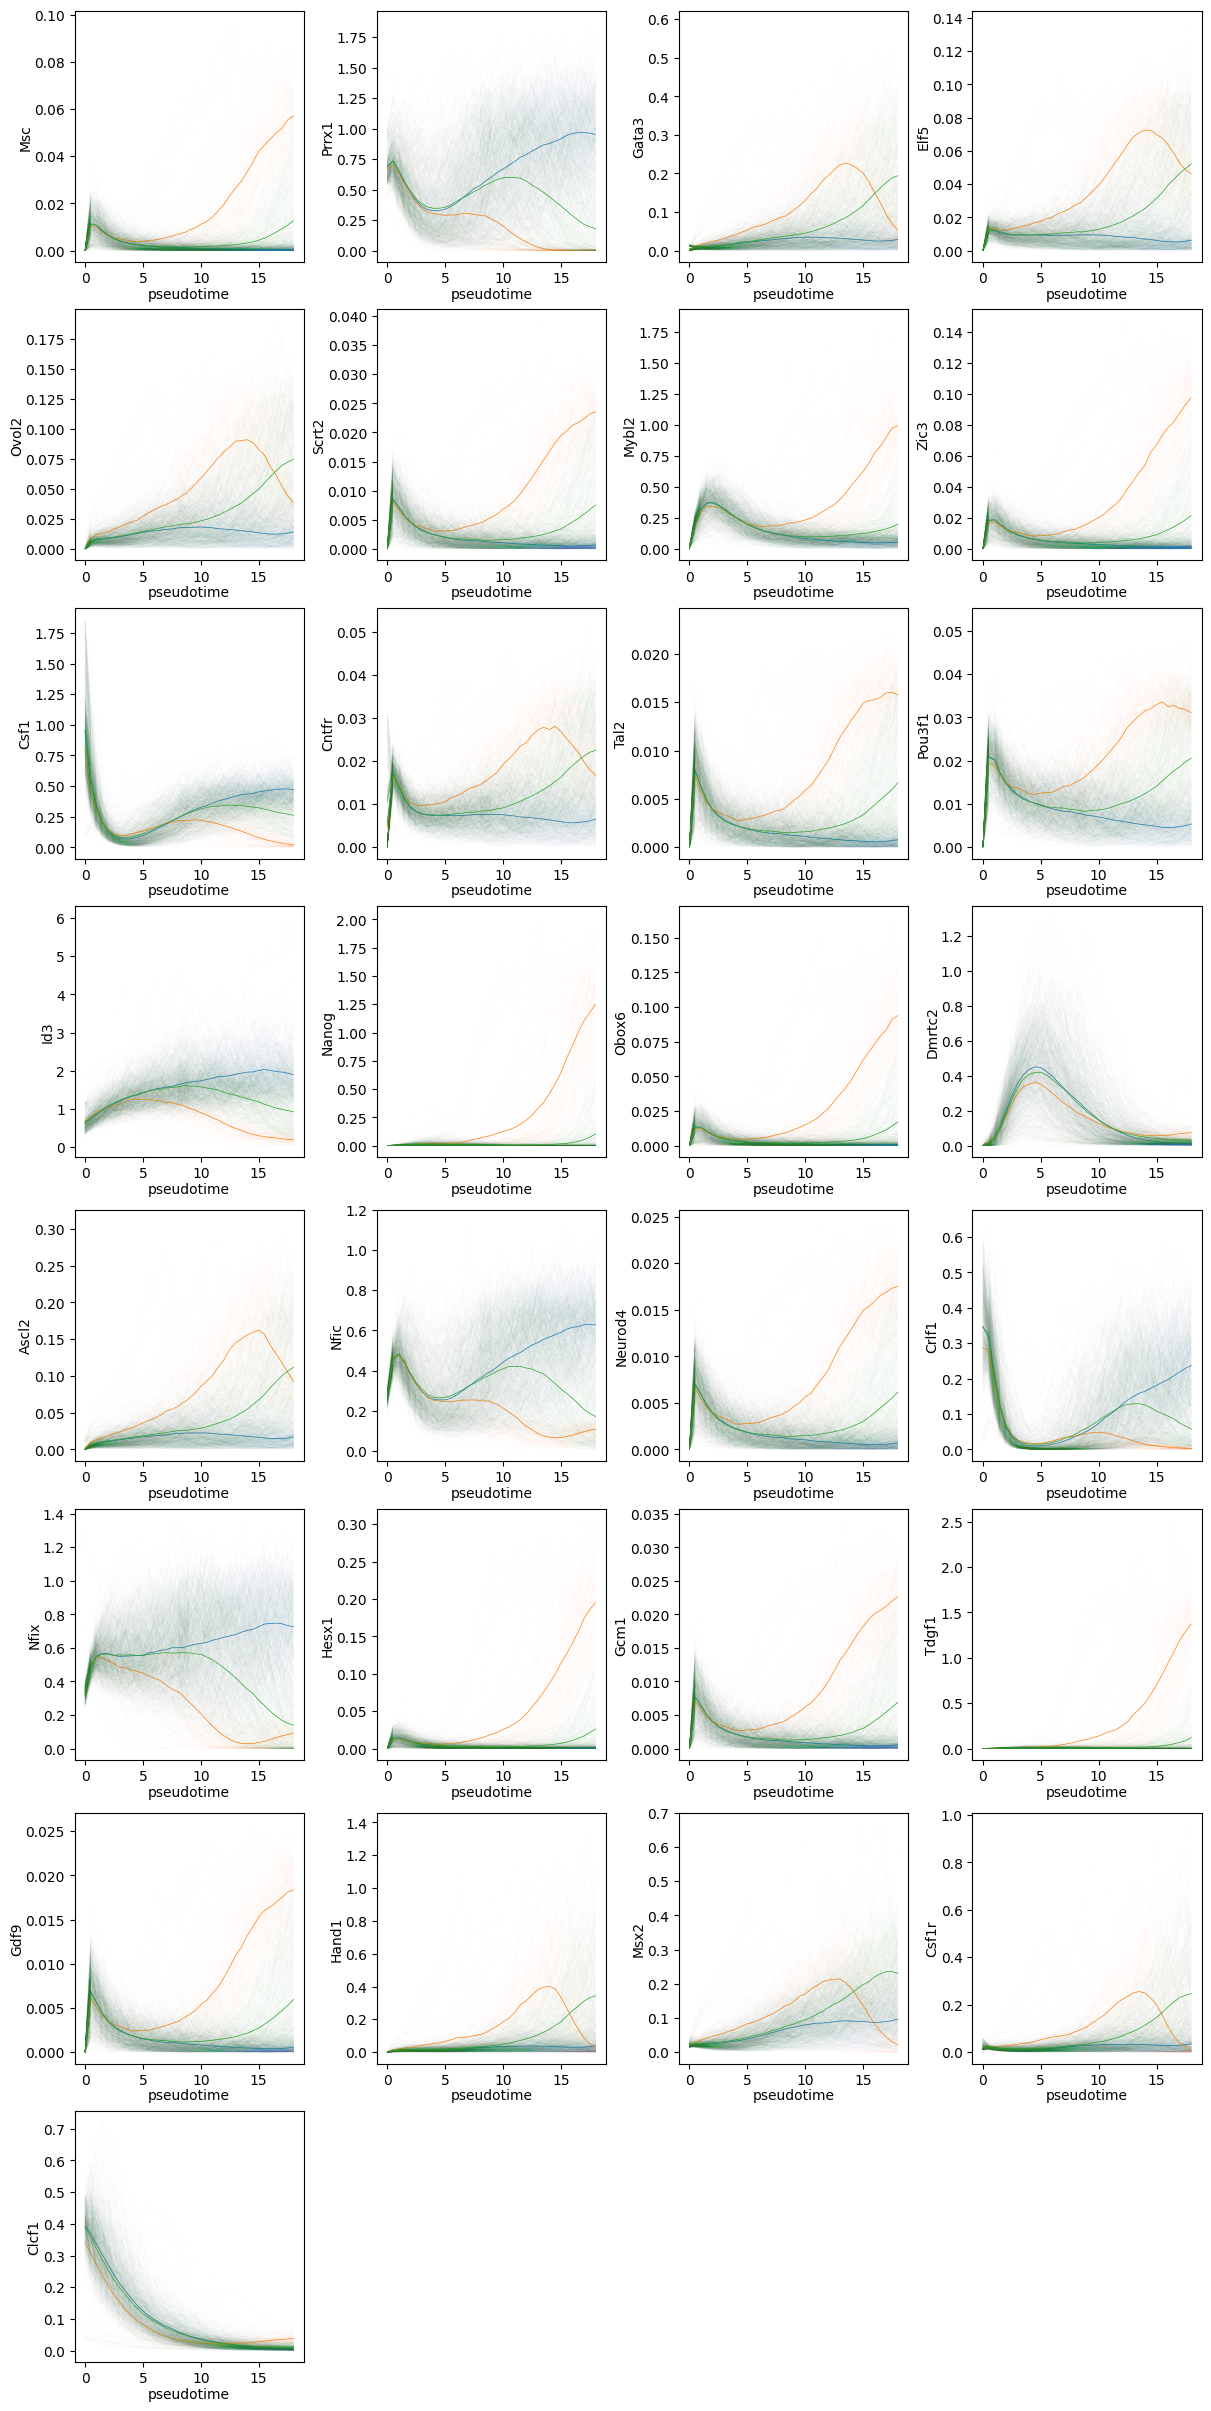

In [20]:
n_rows = dataset.n_genes() // 4 + 1
n_cols = 4
fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3), layout="constrained"
)
alpha = 0.01

for idx in range(dataset.n_genes()):
    ax = axs.flat[idx]
    for i in range(adata.uns["bowside"]["trajectories"].shape[0]):
        cluster_simulations = (
            adata.uns["bowside"]["trajectory_inference_clusters"] == i + 1
        )
        ax.plot(
            dataset.time_points.cpu(),
            adata.uns["bowside"]["simulations"][:, cluster_simulations, idx],
            color=f"C{i}",
            alpha=alpha,
            linewidth=0.5,
            rasterized=True,
        )
        ax.plot(
            dataset.time_points.cpu(),
            adata.uns["bowside"]["trajectories"][i, :, idx],
            c=f"C{i}",
            lw=0.5,
        )
    ax.set_xlabel("pseudotime", labelpad=1.0)
    ax.set_ylabel(dataset.gene_names[idx], labelpad=1.0)  # type: ignore

for ax in axs.flat[dataset.n_genes():]:
    ax.set_axis_off()

In [21]:
# Predict fate for KO simulations
gm_time_series = GaussianMixtureTimeseries(
    adata.uns["bowside"]["simulations"],
    ts.detach().numpy(),
    adata.uns["bowside"]["trajectory_inference_clusters"],
    allow_singular=True,
)
cluster_labels_ko = {}
for gene in dataset.gene_names:
    simulations_ko = adata.uns["bowside"][f"simulations_ko_{gene}"]
    samples = simulations_ko.reshape(-1, simulations_ko.shape[-1])
    probabilities = gm_time_series.predict_proba(
        samples, ts.detach().numpy().repeat(simulations_ko.shape[1])
    ).reshape(simulations_ko.shape[0], simulations_ko.shape[1], -1)
    cluster_labels_ko[gene] = stats.mode(probabilities.argmax(axis=-1), axis=0)[0]
np.savez(OUT_DIR / "cluster_labels_ko.npz", **cluster_labels_ko)

In [22]:
# Save adjacency matrix
adj_mat = pd.DataFrame(
    model.adj.detach().numpy(),
    index=dataset.gene_names,
    columns=dataset.gene_names,
)
adj_mat.to_csv(OUT_DIR / "ipscs_adj_bowside.csv")
adj_list[
    (adj_list["source"].isin(dataset.gene_names))
    & (adj_list["target"].isin(dataset.gene_names))
].to_csv(OUT_DIR / "ipscs_adj_list_tflink.csv", index=False)

In [23]:
# Save AnnData object
with anndata.settings.override(allow_write_nullable_strings=False):
    adata.write_h5ad("../data/ipscs_bowside.h5ad", compression="gzip")